# Water vapour with TRISHNA: 860/910 nm vs Sentinel-2 865/945 nm

## Requirements
- An L1C Sentinel-2 image (SAFE) and a CAMS file (for comparison).

## Tutorial objectives
- Understand the two-band ratio retrieval of the total column water vapour (TCWV).
- Compare the sensitivity of the TRISHNA (910 nm) and S2 (945 nm) absorption bands.
- Estimate the TCWV error due to radiometric noise.
- Apply the ratio method to a Sentinel-2 image and build a pseudo-TRISHNA test.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `scipy`, `pyproj`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 1 core, 4 GB. Run time: ~3 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
plt.rcParams.update({'figure.dpi': 90, 'font.size': 11})

from GRSdriver import Sentinel2Driver
from trishna_tbx.water_vapor import (RatioRetrieval, h2o_optical_thickness, compare_trishna_s2,
                                     noise_error, W_GRID)
from trishna_tbx.io import cams_value

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Principle
The TOA reflectance in an absorption band (910 or 945 nm) divided by a window band
(860/865 nm) is, for a flat surface reflectance and negligible path radiance,

$$\frac{R_{abs}}{R_{win}} = \frac{T_w(\lambda_{abs}, M W)}{T_w(\lambda_{win}, M W)}, \qquad M = \frac{1}{\cos\theta_s} + \frac{1}{\cos\theta_v}$$

The transmittances are computed with the REPTRAN H2O absorption (radcalnet_oc) and integrated
over the band responses.

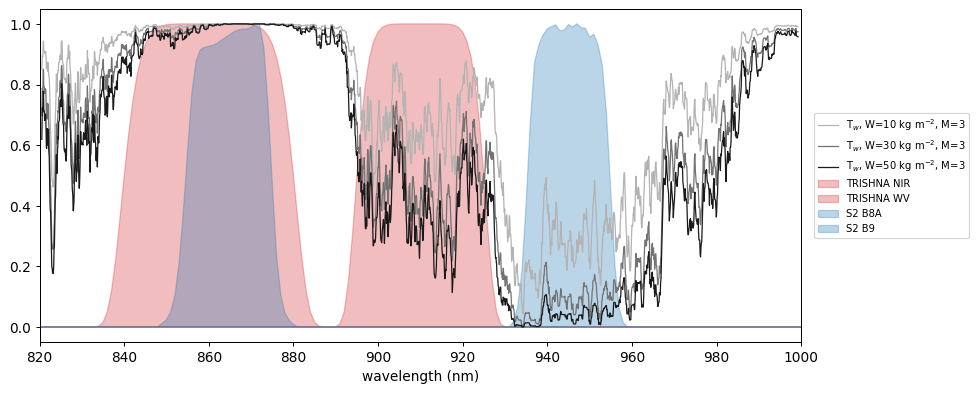

In [3]:
tau = h2o_optical_thickness().sel(wl=slice(820, 1000))
s2 = make_s2()
fig, ax = plt.subplots(figsize=(11, 4.5))
for W, c in zip([10, 30, 50], ['0.7', '0.45', '0.1']):
    T = np.exp(-3 * W * tau).rolling(wl=15, center=True).mean()   # ~3 nm smoothing for display
    ax.plot(tau.wl, T, c=c, lw=1, label=f'T$_w$, W={W} kg m$^{{-2}}$, M=3')
for b, c in [('NIR', 'tab:red'), ('WV', 'tab:red')]:
    ax.fill_between(TRISHNA.srf.wl, TRISHNA.srf.sel(band=b), color=c, alpha=.3, label=f'TRISHNA {b}')
for b in ['B8A', 'B9']:
    ax.fill_between(s2.srf.wl, s2.srf.sel(band=b), color='tab:blue', alpha=.3, label=f'S2 {b}')
ax.set_xlim(820, 1000); ax.set_xlabel('wavelength (nm)'); ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
fig.savefig(THUMB_DIR / 'water_vapor_trishna.png', dpi=70)

## 2. Ratio vs water vapour

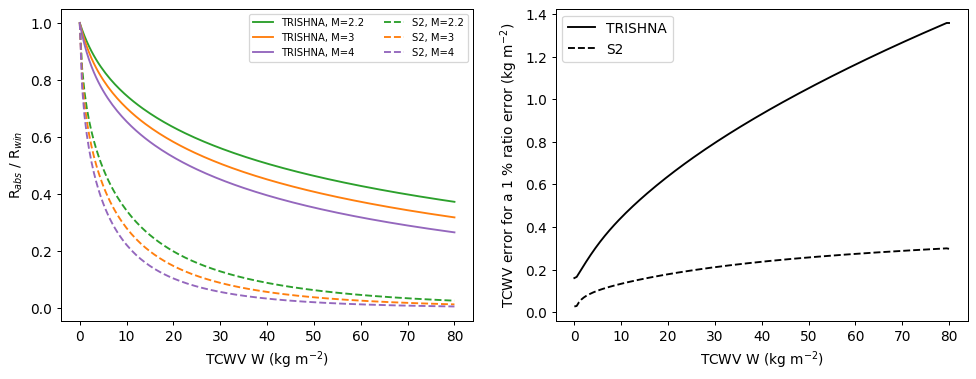

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for s, ls in [('TRISHNA', '-'), ('S2', '--')]:
    r = RatioRetrieval(s)
    for M, c in zip([2.2, 3, 4], ['tab:green', 'tab:orange', 'tab:purple']):
        r.ratio_lut.sel(M=M, method='nearest').plot(ax=axs[0], ls=ls, c=c, label=f'{s}, M={M}')
c = compare_trishna_s2(3.)
for s, ls in [('TRISHNA', '-'), ('S2', '--')]:
    c.dW_for_1pct_ratio_error.sel(sensor=s).plot(ax=axs[1], ls=ls, c='k', label=s)
axs[0].set_ylabel('R$_{abs}$ / R$_{win}$'); axs[0].legend(fontsize=8, ncol=2)
axs[1].set_ylabel('TCWV error for a 1 % ratio error (kg m$^{-2}$)'); axs[1].legend()
for ax in axs: ax.set_xlabel('TCWV W (kg m$^{-2}$)'); ax.set_title('')

The 910 nm band absorbs less: its ratio does not saturate in humid atmospheres (S2 ratio
falls to ~0.03 for W = 60 kg m-2), which motivated the TRISHNA choice. The price is a lower
sensitivity per unit of W, so errors on the ratio (noise, surface spectral slope) cost more.

## 3. Noise-propagated TCWV error
For a flat surface reflectance `rho`, with the requirement SNRs (TRISHNA WV: 50 at Lmin;
S2 B9: 114 at 9 W m-2 sr-1 um-1, native 60 m). Path radiance is ignored, so the dark
cases (rho = 0.01, water) are optimistic.

Text(0.5, 1.0, '')

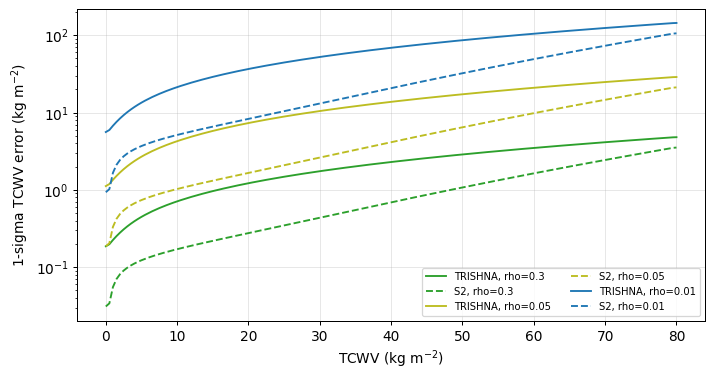

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for rho, c in zip([0.3, 0.05, 0.01], ['tab:green', 'tab:olive', 'tab:blue']):
    for s, ls in [('TRISHNA', '-'), ('S2', '--')]:
        noise_error(s, rho, m=3., sza=48.19).plot(ax=ax, c=c, ls=ls, label=f'{s}, rho={rho}')
ax.set_yscale('log'); ax.set_ylabel('1-sigma TCWV error (kg m$^{-2}$)'); ax.set_xlabel('TCWV (kg m$^{-2}$)')
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.3); ax.set_title('')

## 4. Application to a Sentinel-2 image (865/945 nm)
TOA reflectances at 60 m, per-pixel air mass from the GRSdriver angles. The CAMS TCWV at the
image centre is given for comparison.

In [6]:
drv = Sentinel2Driver(S2_L1C, band_idx=[2, 8, 9], resolution=60, resolution_angle=60, subset=SUBSET)
drv.load_product()
p = drv.prod
r865, r945 = p.bands.sel(wl=865).astype(float), p.bands.sel(wl=945).astype(float)
vza = p.vza.sel(wl=945)
water = ((p.bands.sel(wl=560) - r865) / (p.bands.sel(wl=560) + r865)) > 0.05

W_s2 = xr.DataArray(RatioRetrieval('S2').retrieve(r865.values, r945.values, p.sza.values, vza.values),
                    dims=('y', 'x'), coords={'y': p.y, 'x': p.x})

from pyproj import Transformer
lon, lat = Transformer.from_crs(32631, 4326, always_xy=True).transform(float(p.x.mean()), float(p.y.mean()))
W_cams = float(cams_value(CAMS_FILE, 'tcwv', p.time.values, lon, lat)[0])
print(f'CAMS TCWV: {W_cams:.1f} kg m-2;  S2 ratio retrieval, land median: {float(W_s2.where(~water).median()):.1f};'
      f' water median: {float(W_s2.where(water).median()):.1f}')

CAMS TCWV: 14.9 kg m-2;  S2 ratio retrieval, land median: 11.9; water median: 11.6


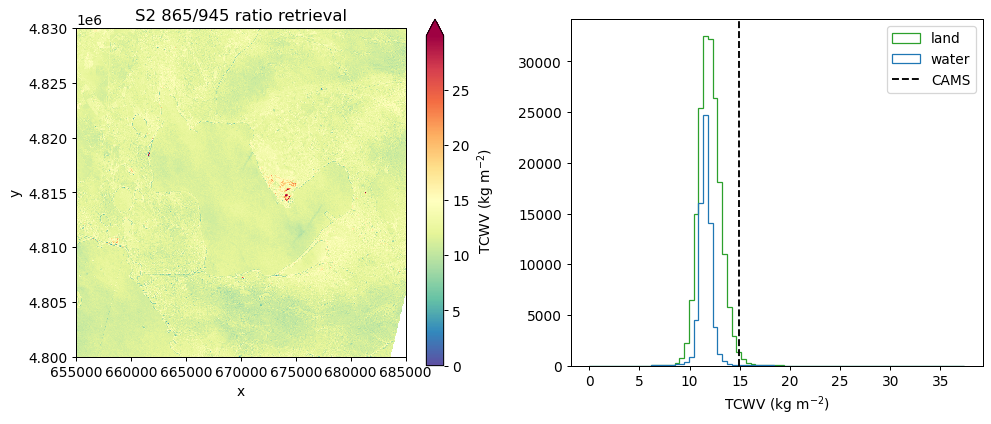

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
W_s2.plot(ax=axs[0], vmin=0, vmax=2 * W_cams, cmap='Spectral_r', cbar_kwargs={'label': 'TCWV (kg m$^{-2}$)'})
axs[0].set_title('S2 865/945 ratio retrieval'); axs[0].set_aspect('equal')
for m, lab, c in [(~water, 'land', 'tab:green'), (water, 'water', 'tab:blue')]:
    axs[1].hist(W_s2.where(m).values.ravel(), bins=np.linspace(0, 2.5 * W_cams, 80), histtype='step', color=c, label=lab)
axs[1].axvline(W_cams, c='k', ls='--', label='CAMS'); axs[1].set_xlabel('TCWV (kg m$^{-2}$)'); axs[1].legend()

Over water, the surface is dark and the signal at 865/945 nm is dominated by the path
radiance, which crosses less water vapour than the surface-reflected light: the decoupled
ratio model underestimates W. **Recommended approach**: retrieve over land/bright pixels and
interpolate over water (W varies slowly), or use the coupled path-length model of hgrs.

Text(0.5, 1.0, 'land retrieval interpolated over water')

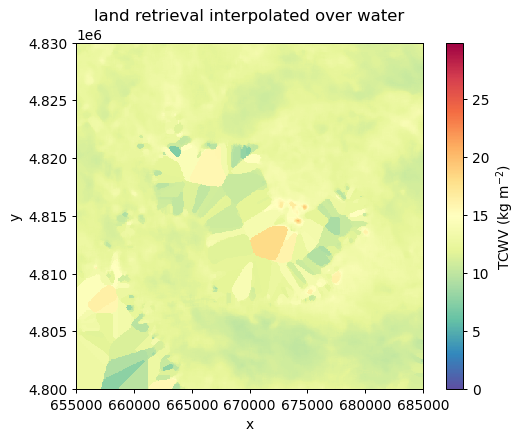

In [8]:
from scipy import ndimage
land = (~water & np.isfinite(W_s2)).values
idx = ndimage.distance_transform_edt(~land, return_distances=False, return_indices=True)
W_filled = W_s2.copy(data=ndimage.median_filter(W_s2.values[tuple(idx)], size=9))
W_filled.plot(vmin=0, vmax=2 * W_cams, cmap='Spectral_r', figsize=(6.5, 5), cbar_kwargs={'label': 'TCWV (kg m$^{-2}$)'})
plt.gca().set_aspect('equal'); plt.title('land retrieval interpolated over water')

## 5. Pseudo-TRISHNA test
The 910 nm band cannot be emulated from Sentinel-2. We build a pseudo-TRISHNA scene: the
S2-derived TCWV (land) is taken as truth, the 860 nm reflectance is the S2 B8A value, and the
910 nm reflectance is computed with the TRISHNA ratio model plus TRISHNA noise. The same is
done for S2 945 nm with S2 noise, so that both retrievals are compared on the same scene.

In [9]:
rng = np.random.default_rng(0)
M = 1 / np.cos(np.radians(p.sza)) + 1 / np.cos(np.radians(vza))
truth = W_filled.where(~water)
res = {}
for s in ['TRISHNA', 'S2']:
    rr = RatioRetrieval(s)
    sens = TRISHNA if s == 'TRISHNA' else s2
    nz = sens.noise_reflectance(float(p.sza.mean())).assign_coords(band=sens.band_names)
    ratio = rr.ratio_lut.interp(W=truth.clip(0.5, 79), M=M.clip(2, 8))
    r_abs = r865 * ratio + float(nz.sel(band=rr.abs)) * rng.standard_normal(r865.shape)
    r_win = r865 + float(nz.sel(band=rr.win)) * rng.standard_normal(r865.shape)
    W = rr.retrieve(r_win.values, r_abs.values, p.sza.values, vza.values)
    res[s] = (W - truth.values)
pd.DataFrame({s: {'bias': np.nanmean(e), 'std': np.nanstd(e), 'p95 |error|': np.nanpercentile(np.abs(e), 95)}
              for s, e in res.items()}).round(2)

,TRISHNA,S2
bias,0.02,-0.00
std,0.76,0.19
p95 |error|,1.50,0.37


## Take-home messages
- 910 nm is less absorbed than 945 nm: no saturation in humid air, but 3-4x less sensitive.
- With the requirement SNR of the TRISHNA WV band (50 at Lmin), the noise-induced TCWV error
  is 2-4x larger than with S2 B9 over bright surfaces. The actual in-flight SNR is key.
- Over water, neither ratio retrieval works directly: use land retrievals + interpolation or
  a coupled radiative transfer model (hgrs).

## References
- Gao, B.-C. & Kaufman, Y. (2003), MODIS near-IR water vapor algorithm, JGR 108.
- TRISHNA mission paper, EGUsphere-2026-4492, section 3.3.3 (need for a water vapor band).